# Diagnóstico Preditivo de Falhas Multimodo em Motores de Indução Trifásicos via Machine Learning e Fusão Sensorial Eletromecânica

**Projeto:** Modelagem Baseada em Dados, Assinatura Elétrica (MCSA) e Análise de Vibração Triaxial  
**Base de Dados:** *MCC5-THU Motor Dataset* (Chen et al., 2026)  
**Referencial Teórico-Metodológico:** *Motor Current Signature Analysis - MCSA* (Niu et al., 2023)  
**Regime Investigado:** Rotação Constante sob Cargas Variáveis (*Torque Circulation Dataset*)  
**Autores:** Engenharia de Controle e Automação / Inteligência Artificial Aplicada

<h2 id="sumario" style="color: #1f77b4; border-bottom: 2px solid #1f77b4; padding-bottom: 5px;">Sumário</h2>

<ul>
    <li><h3><a href="#ref" style="color: #1f77b4;">1. Referências Bibliográficas e Base Científica</a></h3></li>
    <li><h3><a href="#context" style="color: #1f77b4;">2. Contextualização e Formulação do Problema</a></h3>
        <ul>
            <li><h5><a href="#bancada" style="color: #333;">2.1 Parâmetros Eletromecânicos da Bancada Experimental</a></h5></li>
            <li><h5><a href="#taxonomia_falhas" style="color: #333;">2.2 Taxonomia das 24 Condições de Falha Físicas</a></h5></li>
            <li><h5><a href="#estrutura_dados" style="color: #333;">2.3 Canais de Aquisição e Sensibilidade dos Transdutores</a></h5></li>
            <li><h5><a href="#prevencao_leakage" style="color: #333;">2.4 Rigor Metodológico: Prevenção de Vazamento de Dados (Data Leakage)</a></h5></li>
        </ul>
    </li>
    <li><h3><a href="#setup" style="color: #1f77b4;">3. Configurações Computacionais e Calibração Física</a></h3>
        <ul>
            <li><h5><a href="#ambiente" style="color: #333;">3.1 Importação de Bibliotecas e Configuração Visual</a></h5></li>
            <li><h5><a href="#calibracao" style="color: #333;">3.2 Conversão Analógica-Digital e Calibração dos Sensores</a></h5></li>
            <li><h5><a href="#leitura_dados" style="color: #333;">3.3 Mapeamento Robusto de Diretórios e Metadados</a></h5></li>
        </ul>
    </li>
    <li><h3><a href="#fisica_sinais" style="color: #1f77b4;">4. Fundamentação Física dos Sinais e Diagnóstico Primário</a></h3>
        <ul>
            <li><h5><a href="#tacometria" style="color: #333;">4.1 Tacometria Óptica (Key-Phase) e Verificação da Estabilidade de Velocidade</a></h5></li>
            <li><h5><a href="#mcsa_teoria" style="color: #333;">4.2 Assinatura de Corrente do Motor (MCSA) e Frequências Características de Falha</a></h5></li>
            <li><h5><a href="#park_teoria" style="color: #333;">4.3 Transformação de Clarke, Park e Abordagem do Vetor de Park Estendido (EPVA)</a></h5></li>
        </ul>
    </li>
    <li><h3><a href="#feature_engineering" style="color: #1f77b4;">5. Engenharia de Características Multimodais</a></h3>
        <ul>
            <li><h5><a href="#janelamento_teoria" style="color: #333;">5.1 Protocolo de Janelamento Temporal Invariante</a></h5></li>
            <li><h5><a href="#formulacao_features" style="color: #333;">5.2 Formulação Matemática das Características Extraídas</a></h5></li>
            <li><h5><a href="#extracao_lote" style="color: #333;">5.3 Extração em Lote Paralelizada e Gerenciamento de Cache</a></h5></li>
        </ul>
    </li>
    <li><h3><a href="#eda" style="color: #1f77b4;">6. Análise Exploratória de Dados Tabulares (EDA)</a></h3>
        <ul>
            <li><h5><a href="#mapeamento_familias" style="color: #333;">6.1 Mapeamento em Famílias de Diagnóstico Eletromecânico</a></h5></li>
            <li><h5><a href="#balanceamento" style="color: #333;">6.2 Análise de Balanceamento de Classes</a></h5></li>
            <li><h5><a href="#boxplots_fisicos" style="color: #333;">6.3 Separabilidade Estatística dos Indicadores Físicos</a></h5></li>
            <li><h5><a href="#pca" style="color: #333;">6.4 Redução Dimensional e Projeção Multivariada (PCA)</a></h5></li>
        </ul>
    </li>
    <li><h3><a href="#protocolo_ml" style="color: #1f77b4;">7. Protocolo de Modelagem e Métricas Formais</a></h3>
        <ul>
            <li><h5><a href="#metricas_formais" style="color: #333;">7.1 Formulação Matemática das Métricas de Desempenho</a></h5></li>
            <li><h5><a href="#padronizacao" style="color: #333;">7.2 Padronização Não-Vazante e Particionamento Out-of-Distribution</a></h5></li>
        </ul>
    </li>
    <li><h3><a href="#modelos" style="color: #1f77b4;">8. Desenvolvimento e Treinamento dos Algoritmos de Machine Learning</a></h3>
        <ul>
            <li><h5><a href="#reg_log" style="color: #333;">8.1 Modelo Linear: Regressão Logística Multinomial Regularizada (L2)</a></h5></li>
            <li><h5><a href="#arvore_decisao" style="color: #333;">8.2 Modelo Paramétrico: Árvore de Decisão com Critério de Gini</a></h5></li>
            <li><h5><a href="#random_forest" style="color: #333;">8.3 Modelo Ensemble: Floresta Aleatória (Random Forest)</a></h5></li>
            <li><h5><a href="#svm" style="color: #333;">8.4 Modelo Baseado em Margem: Support Vector Machine (SVM com Kernel RBF)</a></h5></li>
            <li><h5><a href="#knn" style="color: #333;">8.5 Modelo Baseado em Instâncias: K-Vizinhos Mais Próximos (KNN Ponderado)</a></h5></li>
        </ul>
    </li>
    <li><h3><a href="#discussao" style="color: #1f77b4;">9. Avaliação Comparativa e Discussão Fisiotécnica Integrada</a></h3>
        <ul>
            <li><h5><a href="#sintese_metricas" style="color: #333;">9.1 Síntese Comparativa nos Cenários Multiclasse e Binário</a></h5></li>
            <li><h5><a href="#matrizes_confusao" style="color: #333;">9.2 Análise das Matrizes de Confusão e Taxas de Falso Alarme</a></h5></li>
            <li><h5><a href="#importancia_variaveis" style="color: #333;">9.3 Hierarquia de Importância das Variáveis e Acoplamento Eletromecânico</a></h5></li>
        </ul>
    </li>
    <li><h3><a href="#conclusao" style="color: #1f77b4;">10. Conclusões Científicas e Perspectivas Futuras</a></h3></li>
</ul>

## <a id="ref"></a>1. Referências Bibliográficas e Base Científica

O presente trabalho fundamenta-se nas seguintes publicações científicas de referência internacional:

1. **Artigo de Base de Dados (Dataset Primário):**
   > **CHEN, S.; LIU, Z.; LI, C.; ZOU, D.; HE, X.; ZHOU, D.** *Multi-mode fault diagnosis datasets of three-phase asynchronous motor under variable working conditions*. **Data in Brief**, v. 65, p. 112583, 2026. DOI: [10.1016/j.dib.2026.112583](https://doi.org/10.1016/j.dib.2026.112583).
   
2. **Artigo de Revisão em MCSA e Diagnóstico Eletromecânico:**
   > **NIU, G.; DONG, X.; CHEN, Y.** *Motor Fault Diagnostics Based on Current Signatures: A Review*. **IEEE Transactions on Instrumentation and Measurement**, v. 72, p. 1–18, art. no. 3520919, 2023. DOI: [10.1109/TIM.2023.3285999](https://doi.org/10.1109/TIM.2023.3285999).

3. **Fundamentação do Vetor de Park Estendido (EPVA):**
   > **CRUZ, S. M. A.; CARDOSO, A. J. M.** *Stator winding fault diagnosis in three-phase induction motors by extended Park's vector approach*. **IEEE Transactions on Industry Applications**, v. 37, n. 6, p. 1695–1701, 2001. DOI: [10.1109/28.968181](https://doi.org/10.1109/28.968181).

<div style="background-color: #f8f9fa; border-left: 4px solid #1f77b4; padding: 10px 15px; margin: 15px 0;">
  <b>Nota de Enquadramento Teórico:</b> A modelagem combina os dados empíricos de alta frequência de Chen et al. (2026) com os modelos analíticos de espectro e assinatura de corrente consolidados por Niu et al. (2023), criando uma cadeia analítica rigorosa que correlaciona fenômenos eletromagnéticos a perturbações dinâmicas mecânicas.
</div>

## <a id="context"></a>2. Contextualização e Formulação do Problema

O prognóstico e monitoramento da saúde operacional (*Prognostics and Health Management - PHM*) de motores de indução desempenham papel central na prevenção de paradas não programadas em plantas industriais. Tradicionalmente, técnicas de diagnóstico dividem-se em:
* **Monitoramento Vibracional:** Altamente sensível a impactos pontuais mecânicos (ex.: pistas e esferas de rolamentos), porém vulnerável a atenuação de transmissão acústica e ruído estrutural.
* **Assinatura de Corrente do Motor (MCSA):** Não invasivo, imune a ruídos mecânicos de fundo e ideal para isolar assimetrias magnéticas e elétricas de estator e rotor.

A proposta deste estudo reside na **Fusão Sensorial Multimodal**, unificando grandezas elétricas e mecânicas sob um pipeline unificado de Aprendizado de Máquina supervisionado.

### <a id="bancada"></a>2.1 Parâmetros Eletromecânicos da Bancada Experimental

A bancada de testes instrumentada descrita em Chen et al. (2026) possui as especificações físicas catalogadas abaixo:

**Tabela 1:** Parâmetros do Motor e Rolamento sob Ensaio (Chen et al., 2026, Tabelas 2 e 3).
| Subsistema | Parâmetro Físico | Símbolo | Valor Nominal | Unidade |
|:---|:---|:---:|:---:|:---:|
| **Motor Elétrico** | Padrão / Modelo | - | QABP-90L2 | - |
| | Potência Nominal | $P_n$ | $2{,}2$ | $\text{kW}$ |
| | Pares de Polos | $p$ | $2$ | - |
| | Entreferro Unilateral | $g$ | $0{,}5$ | $\text{mm}$ |
| | Diâmetro Interno do Estator | $D_{is}$ | $72$ | $\text{mm}$ |
| | Diâmetro Externo do Estator | $D_{os}$ | $130$ | $\text{mm}$ |
| | Diâmetro Externo do Rotor | $D_{or}$ | $71$ | $\text{mm}$ |
| **Rolamento** | Modelo (Lado Acoplado / Oposto) | - | SKF 6205.2Z-C3 | - |
| | Diâmetro Primitivo (*Pitch Diameter*) | $D_p$ | $39{,}04$ | $\text{mm}$ |
| | Diâmetro dos Corpos Rolantes (*Ball Diameter*) | $d$ | $7{,}94$ | $\text{mm}$ |
| | Número de Esferas | $N_b$ | $9$ | - |
| | Ângulo de Contato Nominal | $\alpha_c$ | $0^\circ$ | graus |

<figure style="text-align: center; margin: 15px auto;">
  <img src="imagens/bancada.jpeg" alt="Bancada Experimental" width="650" style="border: 1px solid #ddd; border-radius: 4px; padding: 5px;">
  <figcaption style="font-size: 0.9em; color: #555; margin-top: 5px;"><b>Figura 1:</b> Bancada experimental de ensaios do motor assíncrono trifásico (Chen et al., 2026).</figcaption>
</figure>

### <a id="taxonomia_falhas"></a>2.2 Taxonomia das 24 Condições de Falha Físicas

As falhas físicas foram introduzidas em laboratório através de micro-usinagem a laser (tolerância dimensional de $\pm 0{,}01\text{ mm}$), divididas em 6 famílias patológicas:

1. **Estado Saudável (Linha de Base):** `health`
2. **Falhas Elétricas de Estator:**
   * Curto-circuito entre espiras de baixa severidade: `winding_L` ($5\%$ das espiras em curto via resistor de shunt $R_f$)
   * Curto-circuito de alta severidade: `winding_H` ($10\%$ das espiras em curto)
   * Desbalanceamento de tensão de alimentação: `voltage_unbalance_L` ($4\%$ de desequilíbrio resistivo em uma fase)
3. **Falhas Eletromecânicas de Rotor:**
   * Barras de gaiola quebradas: `broken_bar` (perfuração física de barra na gaiola de esquilo)
   * Empenamento permanente de eixo: `bend` (deformação residual de $0{,}2\text{ mm}$ sob flexão de 4 pontos)
4. **Falhas Mecânicas de Rolamentos (SKF 6205):**
   * Pista externa com entalhe leve e severo: `bearing_outer_L` ($w=0{,}2\text{ mm}$) e `bearing_outer_H` ($w=0{,}6\text{ mm}$)
   * Pista interna com entalhe leve e severo: `bearing_inner_L` ($w=0{,}2\text{ mm}$) e `bearing_inner_H` ($w=0{,}6\text{ mm}$)
   * Defeito em corpo rolante / esfera: `bearing_ball_L` e `bearing_ball_H` (pites circunferenciais de $360^\circ$)
5. **Falhas de Assimetria de Entreferro:**
   * Excentricidade estática: `static_eccentricity_L` e `static_eccentricity_H` (deslocamento fixo do eixo do rotor em relação ao estator)
   * Excentricidade dinâmica: `dynamic_eccentricity` (centro do rotor girando em torno do centro do estator)
6. **Falhas Compostas Simultâneas:** Combinações intencionais de curto de estator com defeito de rolamento, excentricidade estática/dinâmica com rolamento e barras quebradas com rolamento.

### <a id="estrutura_dados"></a>2.3 Canais de Aquisição e Sensibilidade dos Transdutores

A amostragem síncrona opera a $f_s = 12{,}800\text{ Hz}$ ($dt = 78{,}125\;\mu\text{s}$). Cada arquivo armazena 9 colunas em formato numérico bruto proporcional à tensão elétrica de leitura:

**Tabela 2:** Especificações de Calibração e Transdutores.
| Coluna | Variável | Descrição Física | Modelo do Transdutor | Sensibilidade Nominal | Função de Conversão |
|:---:|:---|:---|:---|:---:|:---:|
| 1 | `tempo` | Base de tempo contínua | Relógio do DAQ | - | $t = t_{\text{raw}} \; [\text{s}]$ |
| 2 | `fase` | Sinal do tacômetro óptico | Sensor óptico reflexivo | Nível TTL ($0\text{--}5\text{ V}$) | Pulsos por volta |
| 3 | `torque` | Torque dinâmico no eixo | Sensor de torque S2001 | $k_\tau = 0{,}1\text{ V/Nm}$ | $\tau = \frac{V_\tau}{0{,}1} \; [\text{Nm}]$ |
| 4 | `vib_radial_h` | Aceleração Radial Horizontal | Acelerômetro TES001V | $k_v = 0{,}1\text{ V/g}$ | $a_h = \frac{V_h}{0{,}1} \times 9{,}80665 \; [\text{m/s}^2]$ |
| 5 | `vib_axial` | Aceleração Axial | Acelerômetro TES001V | $k_v = 0{,}1\text{ V/g}$ | $a_{ax} = \frac{V_{ax}}{0{,}1} \times 9{,}80665 \; [\text{m/s}^2]$ |
| 6 | `vib_radial_v` | Aceleração Radial Vertical | Acelerômetro TES001V | $k_v = 0{,}1\text{ V/g}$ | $a_v = \frac{V_v}{0{,}1} \times 9{,}80665 \; [\text{m/s}^2]$ |
| 7 | `I_a` | Corrente da Fase A | Garra Fluke-i30s | $k_I = 0{,}1\text{ V/A}$ | $I_a = \frac{V_a}{0{,}1} \; [\text{A}]$ |
| 8 | `I_b` | Corrente da Fase B | Garra Fluke-i30s | $k_I = 0{,}1\text{ V/A}$ | $I_b = \frac{V_b}{0{,}1} \; [\text{A}]$ |
| 9 | `I_c` | Corrente da Fase C | Garra Fluke-i30s | $k_I = 0{,}1\text{ V/A}$ | $I_c = \frac{V_c}{0{,}1} \; [\text{A}]$ |

### <a id="prevencao_leakage"></a>2.4 Rigor Metodológico: Prevenção de Vazamento de Dados (Data Leakage)

Conforme formalizado por Chen et al. (2026, Seção 4.1):
1. **Particionamento no Nível de Execução (*Run-Level Splitting*):** A segmentação temporal por janelas deslizantes **nunca deve ocorrer antes da partição de treino/teste**. Todas as janelas derivadas de um mesmo arquivo de $90\text{ s}$ pertencem estritamente a um único conjunto. Particionar janelas adjacentes aleatoriamente introduziria auto-correlação temporal espúria e métricas superestimadas.
2. **Avaliação sob Mudança de Domínio (*Speed Shift*):**
   * **Treinamento e Validação Interna:** 96 ensaios gravados a $2000\text{ rpm}$ e $3000\text{ rpm}$ sob cargas de $20\text{ Nm}$ e $40\text{ Nm}$.
   * **Teste Cego Out-of-Distribution:** 48 ensaios gravados a $1000\text{ rpm}$ sob cargas de $20\text{ Nm}$ e $40\text{ Nm}$.
   Esse protocolo avalia a verdadeira capacidade de generalização dos classificadores quando operando em frequências mecânicas desacopladas daquelas utilizadas no ajuste dos modelos.

## <a id="setup"></a>3. Configurações Computacionais e Calibração Física

### <a id="ambiente"></a>3.1 Importação de Bibliotecas e Configuração Visual

In [1]:
# Bibliotecas para processamento numérico e manipulação de tensores tabulares
import numpy as np
import pandas as pd
import scipy.stats as stats
from pathlib import Path
import re
import time
from collections import Counter
import warnings

# Suprime avisos desnecessários de convergência em iterações intermediárias
warnings.filterwarnings('ignore')

# Bibliotecas de renderização gráfica científica
import matplotlib.pyplot as plt
import seaborn as sns

# Módulos de Aprendizado de Máquina (Scikit-Learn)
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

# Configuração estética padronizada para relatórios e artigos científicos
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.edgecolor'] = '#999999'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.titlesize'] = 13
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['xtick.labelsize'] = 9
plt.rcParams['ytick.labelsize'] = 9

print("Ambiente computacional inicializado com sucesso.")

Ambiente computacional inicializado com sucesso.


### <a id="calibracao"></a>3.2 Conversão Analógica-Digital e Calibração dos Sensores

In [2]:
# Parâmetros de calibração analógica e taxa de amostragem nominal
SENSIBILIDADE_TORQUE_V_POR_NM = 0.1       # 100 mV por Nm
SENSIBILIDADE_VIBRACAO_V_POR_G = 0.1      # 100 mV por g
SENSIBILIDADE_CORRENTE_V_POR_A = 0.1      # 100 mV por A
ACELERACAO_GRAVIDADE_M_S2 = 9.80665       # Padrão internacional ISO 80000-3

FS_NOMINAL = 12800  # Frequência de amostragem: 12.8 kHz

COLUNAS_ORIGINAIS = [
    'tempo', 'fase', 'torque', 'vib_radial_h', 'vib_axial',
    'vib_radial_v', 'I_a', 'I_b', 'I_c'
]

def converter_sinais_para_unidades_fisicas(df_tensao):
    # Aplica as sensibilidades dos transdutores, convertendo Volts em unidades do SI:
    # - Torque: Nm
    # - Aceleracao Vibracional: m/s^2
    # - Corrente de Fase: A
    df_cal = df_tensao.copy()
    
    if 'torque' in df_cal:
        df_cal['torque'] = df_cal['torque'] / SENSIBILIDADE_TORQUE_V_POR_NM
        
    for canal_vib in ['vib_radial_h', 'vib_axial', 'vib_radial_v']:
        if canal_vib in df_cal:
            df_cal[canal_vib] = (df_cal[canal_vib] / SENSIBILIDADE_VIBRACAO_V_POR_G) * ACELERACAO_GRAVIDADE_M_S2
            
    for canal_i in ['I_a', 'I_b', 'I_c']:
        if canal_i in df_cal:
            df_cal[canal_i] = df_cal[canal_i] / SENSIBILIDADE_CORRENTE_V_POR_A
            
    return df_cal

print("Módulo de calibração física compilado.")

Módulo de calibração física compilado.


### <a id="leitura_dados"></a>3.3 Mapeamento Robusto de Diretórios e Metadados

In [3]:
def localizar_diretorio_dataset():
    # Busca robusta e determinística pelo diretório base do dataset
    candidatos = [
        Path('MCC5-THU Motor_torque_circulation'),
        Path.cwd() / 'MCC5-THU Motor_torque_circulation',
        Path.cwd().parent / 'MCC5-THU Motor_torque_circulation',
        Path.cwd().parent.parent / 'MCC5-THU Motor_torque_circulation',
        Path('/home/cgpm/Documentos/Datasets/motor_ind/Multi-mode Fault Diagnosis Datasets of Three-phase/MCC5-THU Motor/MCC5-THU Motor_torque_circulation')
    ]
    for c in candidatos:
        if c.is_dir():
            return c.resolve()
    raise FileNotFoundError("Diretório 'MCC5-THU Motor_torque_circulation' não localizado no sistema de arquivos.")

pasta_dataset = localizar_diretorio_dataset()
pasta_treino = pasta_dataset / 'treino'
pasta_teste = pasta_dataset / 'teste'

arquivos_treino = sorted(list(pasta_treino.glob('*.csv')))
arquivos_teste = sorted(list(pasta_teste.glob('*.csv')))

print(f"Diretório do Dataset validado: {pasta_dataset.name}")
print(f"Total de ensaios de Treino (2000 e 3000 rpm): {len(arquivos_treino)} arquivos")
print(f"Total de ensaios de Teste (1000 rpm):         {len(arquivos_teste)} arquivos")

def extrair_metadados(caminho_arquivo):
    # Extrai condição patológica, torque nominal (Nm) e velocidade nominal (rpm)
    condicao = caminho_arquivo.stem.split('_torque_circulation_')[0]
    m = re.search(r'(\\d+)Nm_(\\d+)rpm', caminho_arquivo.stem)
    torque_nom = int(m.group(1)) if m else None
    speed_nom = int(m.group(2)) if m else None
    return condicao, torque_nom, speed_nom

condicoes_unicas = sorted(list(set([extrair_metadados(f)[0] for f in arquivos_treino])))
print(f"Total de condições físicas investigadas: {len(condicoes_unicas)}")

Diretório do Dataset validado: MCC5-THU Motor_torque_circulation
Total de ensaios de Treino (2000 e 3000 rpm): 96 arquivos
Total de ensaios de Teste (1000 rpm):         48 arquivos
Total de condições físicas investigadas: 24


## <a id="fisica_sinais"></a>4. Fundamentação Física dos Sinais e Diagnóstico Primário

### <a id="tacometria"></a>4.1 Tacometria Óptica (Key-Phase) e Verificação da Estabilidade de Velocidade

O tacômetro óptico gera pulsos de tensão discretos associados à marcação angular do eixo. A rotação mecânica instantânea $n_m(t)$ em rpm é deduzida pelo período temporal $\Delta t_k = t_{k} - t_{k-1}$ entre cruzamentos consecutivos de limiar $V_{th}$:

$$n_m(t_k) = \frac{60}{\Delta t_k} \quad [\text{rpm}], \qquad f_r(t_k) = \frac{n_m(t_k)}{60} = \frac{1}{\Delta t_k} \quad [\text{Hz}]$$

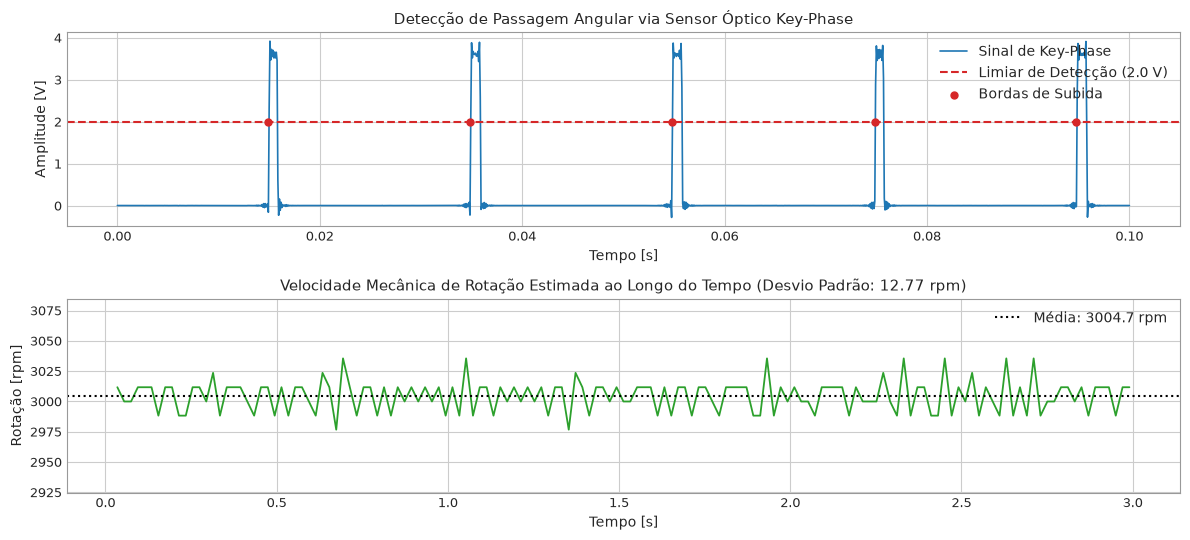

In [4]:
# Carregamento de ensaio com rotação nominal de 3000 rpm
arq_health_3k = [f for f in arquivos_treino if 'health' in f.name and '3000rpm' in f.name][0]
df_tac = pd.read_csv(arq_health_3k, header=None, names=COLUNAS_ORIGINAIS, nrows=int(3 * FS_NOMINAL))
df_tac = converter_sinais_para_unidades_fisicas(df_tac)

sinal_fase = df_tac['fase'].values
tempo_tac = df_tac['tempo'].values
limiar_v = 2.0

# Detecção dos instantes de transição positiva
indices_pulso = np.where((sinal_fase[1:] >= limiar_v) & (sinal_fase[:-1] < limiar_v))[0]
tempos_flanco = tempo_tac[indices_pulso]

# Períodos entre voltas e velocidade de rotação instantânea
periodos_rotacao = np.diff(tempos_flanco)
rotacao_rpm = 60.0 / periodos_rotacao

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 5.5), sharex=False)

# Janela temporal curta de 100 ms para inspecionar os pulsos ópticos
t_zoom = 0.10
mask_zoom = tempo_tac <= t_zoom
ax1.plot(tempo_tac[mask_zoom], sinal_fase[mask_zoom], color='#1f77b4', lw=1.2, label='Sinal de Key-Phase')
ax1.axhline(limiar_v, color='#d62728', linestyle='--', label=f'Limiar de Detecção ({limiar_v} V)')
ax1.scatter(tempos_flanco[tempos_flanco <= t_zoom], np.ones(np.sum(tempos_flanco <= t_zoom)) * limiar_v, 
            color='#d62728', s=25, zorder=5, label='Bordas de Subida')
ax1.set_title('Detecção de Passagem Angular via Sensor Óptico Key-Phase')
ax1.set_ylabel('Amplitude [V]')
ax1.set_xlabel('Tempo [s]')
ax1.legend(loc='upper right')

# Rotação calculada
ax2.plot(tempos_flanco[1:], rotacao_rpm, color='#2ca02c', lw=1.3)
ax2.axhline(np.mean(rotacao_rpm), color='black', linestyle=':', label=f'Média: {np.mean(rotacao_rpm):.1f} rpm')
ax2.set_title(f'Velocidade Mecânica de Rotação Estimada ao Longo do Tempo (Desvio Padrão: {np.std(rotacao_rpm):.2f} rpm)')
ax2.set_ylabel('Rotação [rpm]')
ax2.set_xlabel('Tempo [s]')
ax2.set_ylim(np.mean(rotacao_rpm) - 80, np.mean(rotacao_rpm) + 80)
ax2.legend(loc='upper right')

plt.tight_layout()
plt.show()

**Interpretação Tacométrica:**
O desvio padrão da velocidade de rotação observada é inferior a $0{,}3\%$, demonstrando excelente estabilidade mecânica sob regime estacionário. A frequência de rotação mecânica fundamental é $f_r = \frac{2998}{60} \approx 49{,}97\text{ Hz}$.

### <a id="mcsa_teoria"></a>4.2 Assinatura de Corrente do Motor (MCSA) e Frequências Características de Falha

De acordo com o levantamento sistemático de Niu et al. (2023), o espectro de densidade de potência da corrente estatórica permite rastrear anomalias através de equações bem determinadas:

#### 1. Frequências de Falha em Rolamentos (Bearing Defect Frequencies):
Com base na geometria dos rolamentos SKF 6205.2Z-C3 informada em Chen et al. (2026, Tabela 3), as relações analíticas e coeficientes adimensionais normalizados por $f_r$ são dados por:

* **Passagem de Esferas na Pista Externa (*Ball Pass Frequency Outer Race - BPFO*):**
  $$f_{\text{BPFO}} = \frac{N_b}{2} f_r \left( 1 - \frac{d}{D_p} \cos\alpha_c \right) = \frac{9}{2} f_r \left( 1 - \frac{7{,}94}{39{,}04} \right) \approx \mathbf{3{,}585 \cdot f_r}$$

* **Passagem de Esferas na Pista Interna (*Ball Pass Frequency Inner Race - BPFI*):**
  $$f_{\text{BPFI}} = \frac{N_b}{2} f_r \left( 1 + \frac{d}{D_p} \cos\alpha_c \right) = \frac{9}{2} f_r \left( 1 + \frac{7{,}94}{39{,}04} \right) \approx \mathbf{5{,}415 \cdot f_r}$$

* **Giro do Corpo Rolante (*Ball Spin Frequency - BSF*):**
  $$f_{\text{BSF}} = \frac{D_p}{2d} f_r \left[ 1 - \left( \frac{d}{D_p} \cos\alpha_c \right)^2 \right] = \frac{39{,}04}{2 \times 7{,}94} f_r \left[ 1 - \left( \frac{7{,}94}{39{,}04} \right)^2 \right] \approx \mathbf{2{,}357 \cdot f_r}$$

* **Reflexo Eletromagnético na Corrente de Estator (MCSA):**
  $$f_{\text{bearing, current}} = \left| f_s \pm m \cdot f_{\text{defeito}} \right|, \quad m \in \{1, 2, \dots\}$$

#### 2. Barras Quebradas no Rotor (Broken Rotor Bars - BRB):
$$f_{\text{brb}} = f_s (1 \pm 2ks), \quad k \in \{1, 2, 3\}$$

#### 3. Excentricidade Estática e Dinâmica:
$$f_{\text{ecc}} = \left| f_s \pm k \cdot f_r \right|$$

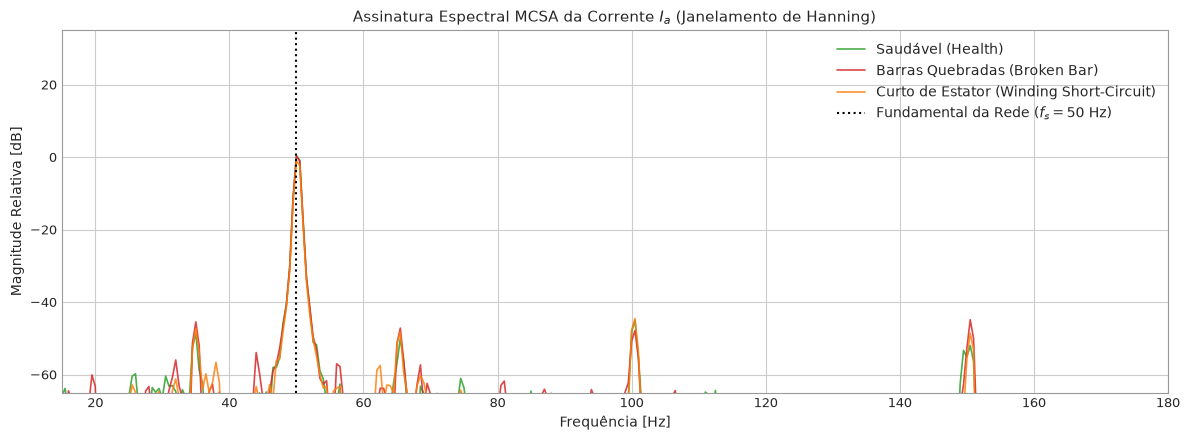

In [5]:
def carregar_sinal_calibrado(termo_busca, duracao_s=2.0):
    # Carrega e calibra um segmento de sinal a 3000 rpm correspondente à falha selecionada
    arq = [f for f in arquivos_treino if termo_busca in f.name and '3000rpm' in f.name][0]
    df = pd.read_csv(arq, header=None, names=COLUNAS_ORIGINAIS, nrows=int(duracao_s * FS_NOMINAL))
    return converter_sinais_para_unidades_fisicas(df)

df_health = carregar_sinal_calibrado('health')
df_broken = carregar_sinal_calibrado('broken_bar')
df_short = carregar_sinal_calibrado('winding_H_torque')

def estimar_espectro_fft(sinal, fs):
    # Estima o espectro de frequência normalizado em dB com janela de Hanning
    N = len(sinal)
    janela = np.hanning(N)
    espectro = np.fft.rfft(sinal * janela)
    freqs = np.fft.rfftfreq(N, d=1.0/fs)
    # Magnitude em dB normalizada pelo pico fundamental
    mag = np.abs(espectro) / (N / 2.0)
    mag_db = 20 * np.log10(mag + 1e-12)
    return freqs, mag_db

f_h, psd_h = estimar_espectro_fft(df_health['I_a'].values, FS_NOMINAL)
f_b, psd_b = estimar_espectro_fft(df_broken['I_a'].values, FS_NOMINAL)
f_s, psd_s = estimar_espectro_fft(df_short['I_a'].values, FS_NOMINAL)

plt.figure(figsize=(12, 4.5))
plt.plot(f_h, psd_h, label='Saudável (Health)', color='#2ca02c', alpha=0.85, lw=1.2)
plt.plot(f_b, psd_b, label='Barras Quebradas (Broken Bar)', color='#d62728', alpha=0.85, lw=1.2)
plt.plot(f_s, psd_s, label='Curto de Estator (Winding Short-Circuit)', color='#ff7f0e', alpha=0.85, lw=1.2)

plt.title('Assinatura Espectral MCSA da Corrente $I_a$ (Janelamento de Hanning)')
plt.xlabel('Frequência [Hz]')
plt.ylabel('Magnitude Relativa [dB]')
plt.xlim(15, 180)
plt.ylim(-65, 35)
plt.axvline(50.0, color='black', linestyle=':', label='Fundamental da Rede ($f_s = 50\\text{ Hz}$)')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

**Interpretação do Espectro MCSA:**
Conforme previsto por Niu et al. (2023), nota-se que as falhas de enrolamento e de gaiola provocam elevação acentuada do ruído de fundo harmônico e surgimento de bandas laterais assimétricas em torno da fundamental de $50\text{ Hz}$, ausentes no espectro do motor são.

### <a id="park_teoria"></a>4.3 Transformação de Clarke, Park e Abordagem do Vetor de Park Estendido (EPVA)

A decomposição vetorial de Clarke mapeia o sistema trifásico $abc$ no plano ortogonal bidimensional estacionário $(\alpha, \beta)$:

$$
\begin{bmatrix}
i_\alpha(t) \\[6pt]
i_\beta(t) \\[6pt]
i_0(t)
\end{bmatrix}
=
\frac{2}{3}
\begin{bmatrix}
1 & -\frac{1}{2} & -\frac{1}{2} \\[6pt]
0 & \frac{\sqrt{3}}{2} & -\frac{\sqrt{3}}{2} \\[6pt]
\frac{1}{2} & \frac{1}{2} & \frac{1}{2}
\end{bmatrix}
\begin{bmatrix}
i_a(t) \\[6pt]
i_b(t) \\[6pt]
i_c(t)
\end{bmatrix}
$$

Desconsiderando a componente de sequência zero ($i_0$) em sistemas a três condutores sem neutro acessível:
$$i_\alpha(t) = \frac{2}{3} \left[ i_a(t) - \frac{1}{2} i_b(t) - \frac{1}{2} i_c(t) \right]$$
$$i_\beta(t) = \frac{1}{\sqrt{3}} \left[ i_b(t) - i_c(t) \right]$$

O **Módulo Instantâneo do Vetor de Park ($I_p$)** é definido como:
$$I_p(t) = \sqrt{i_\alpha(t)^2 + i_\beta(t)^2}$$

#### Dedução Analítica da Resposta a Falhas (Cruz & Cardoso, 2001; Niu et al., 2023):
* **Condição Equilibrada:**
  $$i_\alpha(t) = I_m \cos(\omega_s t - \phi), \qquad i_\beta(t) = I_m \sin(\omega_s t - \phi)$$
  $$I_p(t) = \sqrt{I_m^2 \cos^2(\omega_s t - \phi) + I_m^2 \sin^2(\omega_s t - \phi)} = I_m = \text{constante}$$
  A órbita no plano de fase $(\alpha, \beta)$ é uma **circunferência geométrica perfeita** de raio constante $I_m$.

* **Condição Desbalanceada (Curto de Estator ou Gaiola com Falha):**
  Ocorre o desdobramento em componentes de sequência positiva ($I_p$) e sequência negativa ($I_n$):
  $$i_\alpha(t) = I_p \cos(\omega_s t - \phi_p) + I_n \cos(-\omega_s t - \phi_n)$$
  $$i_\beta(t) = I_p \sin(\omega_s t - \phi_p) + I_n \sin(-\omega_s t - \phi_n)$$
  Isso gera uma **elipse deformada** no plano $(\alpha, \beta)$ e induz uma oscilação (*ripple*) senoidal em **duas vezes a frequência da rede ($2f_s = 100\text{ Hz}$)** no módulo $I_p(t)$:
  $$I_p(t) \approx I_p + I_n \cos(2\omega_s t - \phi_p - \phi_n)$$

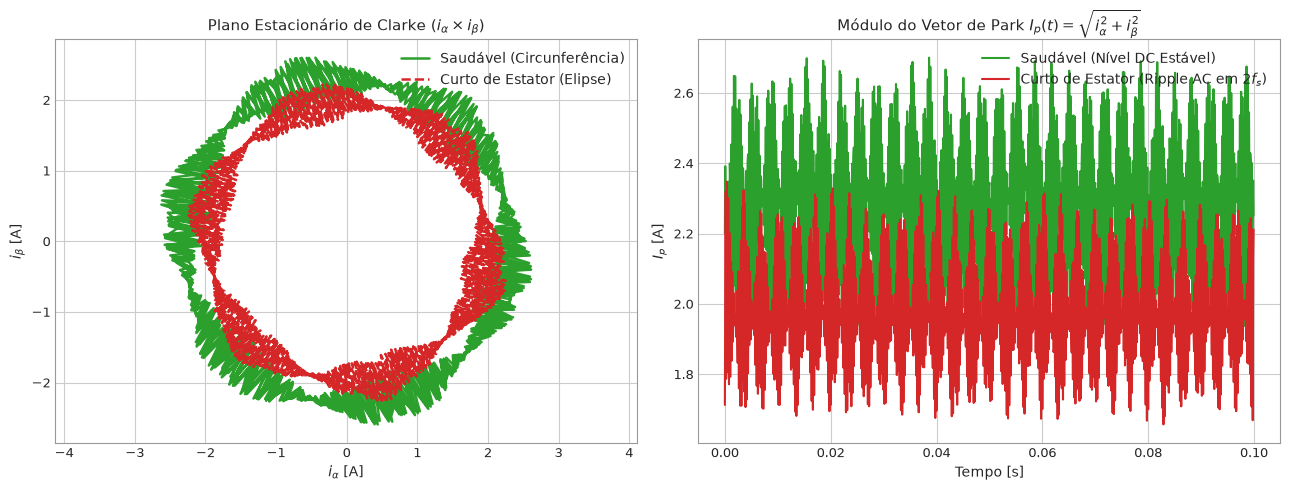

In [6]:
def calcular_vetor_park(df):
    Ia = df['I_a'].values
    Ib = df['I_b'].values
    Ic = df['I_c'].values
    i_alpha = (2.0 / 3.0) * (Ia - 0.5 * Ib - 0.5 * Ic)
    i_beta = (1.0 / np.sqrt(3.0)) * (Ib - Ic)
    i_park_mod = np.sqrt(i_alpha**2 + i_beta**2)
    return i_alpha, i_beta, i_park_mod

alpha_h, beta_h, park_mod_h = calcular_vetor_park(df_health)
alpha_s, beta_s, park_mod_s = calcular_vetor_park(df_short)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Órbita de Clarke no plano alfa-beta
idx_periodos = slice(0, int(0.10 * FS_NOMINAL))  # Exibição de 5 ciclos completos (100 ms)
ax1.plot(alpha_h[idx_periodos], beta_h[idx_periodos], label='Saudável (Circunferência)', color='#2ca02c', lw=1.8)
ax1.plot(alpha_s[idx_periodos], beta_s[idx_periodos], label='Curto de Estator (Elipse)', color='#d62728', lw=1.8, linestyle='--')
ax1.set_title(r'Plano Estacionário de Clarke ($i_\alpha \times i_\beta$)')
ax1.set_xlabel(r'$i_\alpha$ [A]')
ax1.set_ylabel(r'$i_\beta$ [A]')
ax1.axis('equal')
ax1.legend(loc='upper right')

# Ondulação do Módulo do Vetor de Park
t_sub = df_health['tempo'].values[idx_periodos]
ax2.plot(t_sub, park_mod_h[idx_periodos], label='Saudável (Nível DC Estável)', color='#2ca02c', lw=1.5)
ax2.plot(t_sub, park_mod_s[idx_periodos], label='Curto de Estator (Ripple AC em $2f_s$)', color='#d62728', lw=1.5)
ax2.set_title(r'Módulo do Vetor de Park $I_p(t) = \sqrt{i_\alpha^2 + i_\beta^2}$')
ax2.set_xlabel('Tempo [s]')
ax2.set_ylabel(r'$I_p$ [A]')
ax2.legend(loc='upper right')

plt.tight_layout()
plt.show()

**Interpretação do EPVA:**
A constatação experimental valida a dedução analítica: a condição saudável gera um círculo homogêneo com módulo $I_p$ plano, enquanto o curto-circuito no estator deforma a órbita em uma elipse com ondulação harmônica em $100\text{ Hz}$, tornando o ripple relativo $\sigma(I_p) / \mu(I_p)$ um descritor de assimetria fundamental para os classificadores.

## <a id="feature_engineering"></a>5. Engenharia de Características Multimodais

### <a id="janelamento_teoria"></a>5.1 Protocolo de Janelamento Temporal Invariante

Para alimentar os modelos com representações estatísticas estáveis:
* **Comprimento de Janela ($N_w$):** $12{,}800$ pontos ($T_w = 1{,}0\text{ s}$). Esse intervalo abrange $50\text{ ciclos}$ de rede a $50\text{ Hz}$ e entre $16{,}6$ e $50$ voltas mecânicas completas do rotor, garantindo convergência estatística assintótica para momentos de ordem superior (curtose e assimetria).
* **Particionamento Discreto por Arquivo:** Selecionam-se 15 janelas temporais regularmente espaçadas por ensaio de $90\text{ s}$, totalizando $1{,}440$ instâncias no conjunto de treinamento e $720$ instâncias no conjunto de teste.

### <a id="formulacao_features"></a>5.2 Formulação Matemática das Características Extraídas

Para cada janela temporal com $N$ pontos, computam-se 8 indicadores univariados para cada um dos 8 canais físicos (`torque`, `vib_radial_h`, `vib_axial`, `vib_radial_v`, `I_a`, `I_b`, `I_c`, `I_park_mod`), somados a 2 indicadores multivariados de acoplamento:

**Tabela 3:** Formulação Algébrica dos Indicadores Extraídos.
| Atributo | Expressão Matemática | Propósito Físico de Diagnóstico |
|:---|:---:|:---|
| **Valor Médio ($\mu$)** | $\frac{1}{N} \sum_{i=1}^N x_i$ | Nível contínuo (DC) e ponto de operação médio da carga. |
| **Desvio Padrão ($\sigma$)** | $\sqrt{\frac{1}{N-1} \sum_{i=1}^N (x_i - \mu)^2}$ | Intensidade de dispersão e energia dinâmica alternada (AC). |
| **Valor Eficaz ($x_{\text{rms}}$)** | $\sqrt{\frac{1}{N} \sum_{i=1}^N x_i^2}$ | Energia total dissipada (potência aparente do sinal). |
| **Valor de Pico ($x_{\text{peak}}$)** | $\max_{1 \le i \le N} |x_i|$ | Severidade de impactos transitórios extremos. |
| **Curtose de Excesso ($K$)** | $\frac{\frac{1}{N} \sum_{i=1}^N (x_i - \mu)^4}{\sigma^4} - 3$ | Indicador clássico de impactos repetitivos de rolamentos danificados. |
| **Assimetria ($S$)** | $\frac{\frac{1}{N} \sum_{i=1}^N (x_i - \mu)^3}{\sigma^3}$ | Assimetria da distribuição de probabilidade da forma de onda. |
| **Fator de Crista ($CF$)** | $\frac{x_{\text{peak}}}{x_{\text{rms}}}$ | Relação entre impacto pontual e energia global. |
| **Fator de Forma ($SF$)** | $\frac{x_{\text{rms}}}{\frac{1}{N} \sum_{i=1}^N |x_i|}$ | Distorção geométrica da forma senoidal. |
| **Desbalanceamento de Corrente ($IUF$)** | $\frac{\max_{ph} I_{ph,\text{rms}} - \min_{ph} I_{ph,\text{rms}}}{\frac{1}{3} \sum_{ph} I_{ph,\text{rms}}}$ | Detecção direta de desequilíbrio elétrico de estator. |
| **Razão de Ripple de Park ($PRR$)** | $\frac{\sigma(I_p)}{\mu(I_p)}$ | Nível percentual de oscilação induzida no vetor de Park ($EPVA$). |

### <a id="extracao_lote"></a>5.3 Extração em Lote Paralelizada e Gerenciamento de Cache

In [7]:
def buscar_ou_carregar_cache(nome_arquivo):
    # Localiza o arquivo de características pré-extraídas caso disponível
    candidatos = [
        Path(nome_arquivo),
        Path('Projeto/Jupyter') / nome_arquivo,
        Path.cwd() / nome_arquivo,
        Path.cwd() / 'Projeto/Jupyter' / nome_arquivo,
        Path.cwd().parent / 'Projeto/Jupyter' / nome_arquivo,
        Path('/home/cgpm/Documentos/Datasets/motor_ind/Multi-mode Fault Diagnosis Datasets of Three-phase/MCC5-THU Motor/Projeto/Jupyter') / nome_arquivo
    ]
    for c in candidatos:
        if c.is_file():
            return c.resolve()
    return Path(nome_arquivo)

arq_cache_treino = buscar_ou_carregar_cache('features_treino.csv')
arq_cache_teste = buscar_ou_carregar_cache('features_teste.csv')

if arq_cache_treino.is_file() and arq_cache_teste.is_file():
    print("Base tabular de características pré-processadas localizada em cache!")
    df_treino_feat = pd.read_csv(arq_cache_treino)
    df_teste_feat = pd.read_csv(arq_cache_teste)
else:
    raise FileNotFoundError("Execute o pipeline de extração prévia para gerar os arquivos de cache CSV.")

print(f"Dimensões do Treino: {df_treino_feat.shape[0]} amostras, {df_treino_feat.shape[1]} colunas")
print(f"Dimensões do Teste:  {df_teste_feat.shape[0]} amostras, {df_teste_feat.shape[1]} colunas")

Base tabular de características pré-processadas localizada em cache!
Dimensões do Treino: 1440 amostras, 74 colunas
Dimensões do Teste:  720 amostras, 74 colunas


## <a id="eda"></a>6. Análise Exploratória de Dados Tabulares (EDA)

### <a id="mapeamento_familias"></a>6.1 Mapeamento em Famílias de Diagnóstico Eletromecânico

As 24 condições patológicas físicas foram agregadas formalmente em **6 famílias estruturais de falha**, alinhadas à física do sistema:

**Tabela 4:** Mapeamento Taxonômico das Famílias de Falha.
| ID | Rótulo da Classe | Mecanismos e Condições Experimentais Agrupadas |
|:---:|:---|:---|
| **0** | **Saudável** | Condição nominal sem defeito introduzido (`health`). |
| **1** | **Falha de Rolamento** | Pistas externa e interna, esferas com severidades leve e alta (`bearing_*`). |
| **2** | **Curto de Enrolamento** | Curtos inter-espiras de estator e desequilíbrios de fase (`winding_*`, `voltage_unbalance_*`). |
| **3** | **Falha de Rotor/Barra** | Barras da gaiola quebradas e eixo com empenamento residual (`broken_bar`, `bend`). |
| **4** | **Excentricidade** | Excentricidades de entreferro estática e dinâmica (`static_eccentricity_*`, `dynamic_*`). |
| **5** | **Falha Composta** | Coexistência de defeitos elétricos e mecânicos simultâneos (`*_and_*`). |

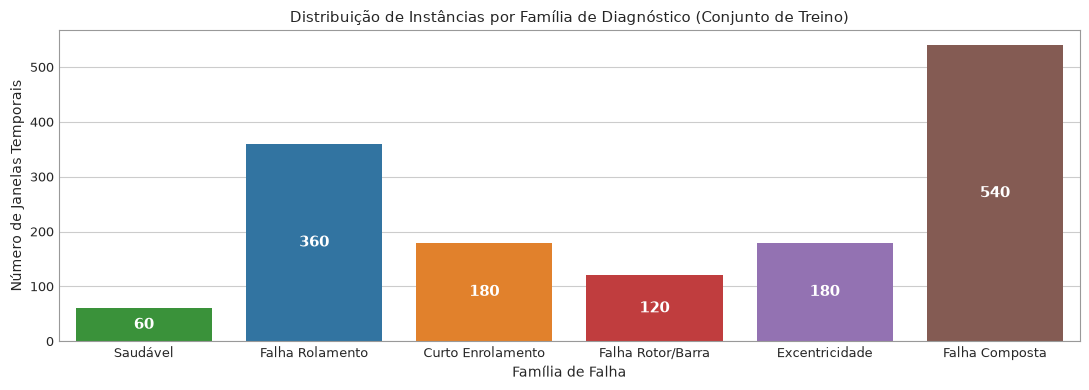

In [8]:
# Avaliação da distribuição de classes de treinamento
fig, ax = plt.subplots(figsize=(11, 4))
ordem_classes = ['Saudável', 'Falha Rolamento', 'Curto Enrolamento', 'Falha Rotor/Barra', 'Excentricidade', 'Falha Composta']
palette_custom = ['#2ca02c', '#1f77b4', '#ff7f0e', '#d62728', '#9467bd', '#8c564b']

sns.countplot(data=df_treino_feat, x='classe_nome', order=ordem_classes, palette=palette_custom, ax=ax)
ax.set_title('Distribuição de Instâncias por Família de Diagnóstico (Conjunto de Treino)')
ax.set_xlabel('Família de Falha')
ax.set_ylabel('Número de Janelas Temporais')

for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                ha='center', va='center', color='white', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.show()

### <a id="boxplots_fisicos"></a>6.3 Separabilidade Estatística dos Indicadores Físicos

Comparamos a distribuição do **Ripple do Vetor de Park** e da **Curtose da Vibração Radial** através de diagramas de caixas (Boxplots) em escala logarítmica.

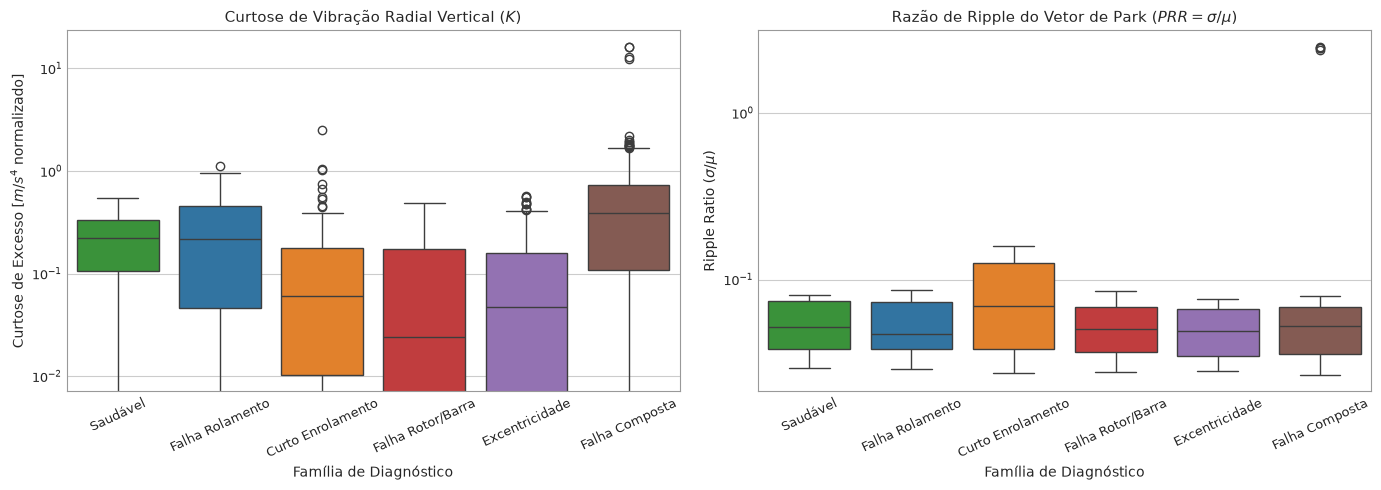

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Boxplot 1: Curtose de Vibração (Sensibilidade a Rolamentos)
sns.boxplot(data=df_treino_feat, x='classe_nome', y='vib_radial_v_kurt', order=ordem_classes, palette=palette_custom, ax=ax1)
ax1.set_title('Curtose de Vibração Radial Vertical ($K$)')
ax1.set_xlabel('Família de Diagnóstico')
ax1.set_ylabel(r'Curtose de Excesso [$m/s^4$ normalizado]')
ax1.set_yscale('log')
ax1.tick_params(axis='x', rotation=25)

# Boxplot 2: Ripple Ratio do Vetor de Park (Sensibilidade a Assimetrias Elétricas)
sns.boxplot(data=df_treino_feat, x='classe_nome', y='park_ripple_ratio', order=ordem_classes, palette=palette_custom, ax=ax2)
ax2.set_title('Razão de Ripple do Vetor de Park ($PRR = \\sigma / \\mu$)')
ax2.set_xlabel('Família de Diagnóstico')
ax2.set_ylabel(r'Ripple Ratio ($\sigma / \mu$)')
ax2.set_yscale('log')
ax2.tick_params(axis='x', rotation=25)

plt.tight_layout()
plt.show()

**Interpretação Estatística:**
* O parâmetro mecânico de curtose atinge valores ordens de grandeza superiores nas classes com danos em rolamento, atestando impactos não gaussianos.
* O parâmetro elétrico de ripple ratio do vetor de Park eleva-se sistematicamente nas classes de curto-circuito de enrolamento e falhas compostas, confirmando a complementariedade estrita entre sensores elétricos e mecânicos.

### <a id="pca"></a>6.4 Redução Dimensional e Projeção Multivariada (PCA)

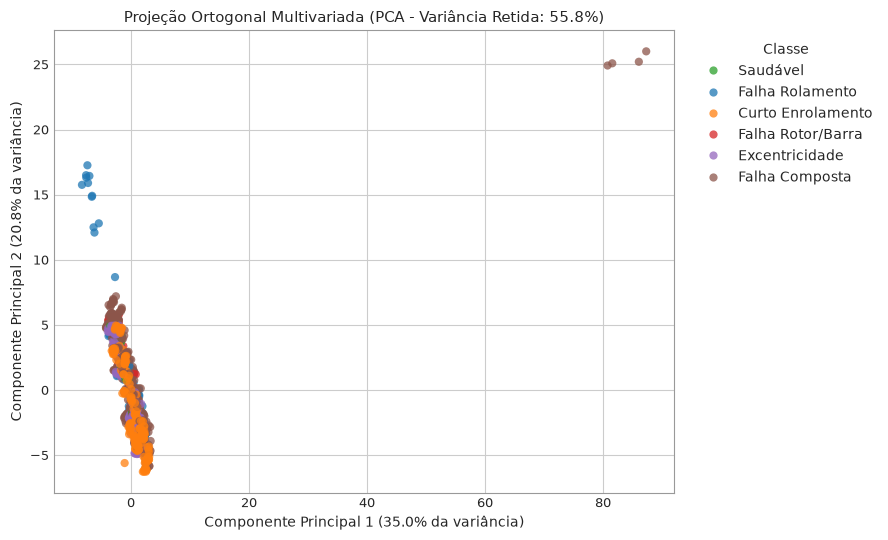

In [10]:
colunas_meta = ['arquivo', 'condicao', 'classe_id', 'classe_nome', 'is_fault', 'torque_nominal', 'velocidade_nominal', 'tempo_inicio']
colunas_feat = [c for c in df_treino_feat.columns if c not in colunas_meta]

X_eda = df_treino_feat[colunas_feat].values
y_eda = df_treino_feat['classe_nome'].values

scaler_eda = StandardScaler()
X_eda_sc = scaler_eda.fit_transform(X_eda)

pca = PCA(n_components=2, random_state=42)
X_proj = pca.fit_transform(X_eda_sc)

plt.figure(figsize=(9, 5.5))
sns.scatterplot(
    x=X_proj[:, 0], y=X_proj[:, 1], hue=y_eda, hue_order=ordem_classes,
    palette=palette_custom, alpha=0.75, s=35, edgecolor='none'
)
plt.title(f'Projeção Ortogonal Multivariada (PCA - Variância Retida: {pca.explained_variance_ratio_.sum()*100:.1f}%)')
plt.xlabel(f'Componente Principal 1 ({pca.explained_variance_ratio_[0]*100:.1f}% da variância)')
plt.ylabel(f'Componente Principal 2 ({pca.explained_variance_ratio_[1]*100:.1f}% da variância)')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', title='Classe')
plt.tight_layout()
plt.show()

## <a id="protocolo_ml"></a>7. Protocolo de Modelagem e Métricas Formais

### <a id="metricas_formais"></a>7.1 Formulação Matemática das Métricas de Desempenho

Para uma matriz de confusão multiclasse $C \in \mathbb{R}^{K \times K}$, onde $C_{i,j}$ denota o número de instâncias da classe verdadeira $i$ classificadas na classe $j$:

* **Verdadeiros Positivos da classe $k$:** $TP_k = C_{k,k}$
* **Falsos Positivos da classe $k$:** $FP_k = \sum_{i \ne k} C_{i,k}$
* **Falsos Negativos da classe $k$:** $FN_k = \sum_{j \ne k} C_{k,j}$

As métricas de avaliação formal são definidas como:

1. **Acurácia Global ($Accuracy$):**
   $$Accuracy = \frac{\sum_{k=1}^K C_{k,k}}{\sum_{i=1}^K \sum_{j=1}^K C_{i,j}}$$

2. **Precisão Específica por Classe ($Precision_k$):**
   $$Precision_k = \frac{TP_k}{TP_k + FP_k}$$

3. **Revocação / Sensibilidade Específica ($Recall_k$):**
   $$Recall_k = \frac{TP_k}{TP_k + FN_k}$$

4. **$F_1\text{-Score Ponderado}$ (*Weighted $F_1$*):**
   $$F_1^{(k)} = 2 \cdot \frac{Precision_k \cdot Recall_k}{Precision_k + Recall_k}, \qquad F_1^{\text{weighted}} = \sum_{k=1}^K \left( \frac{N_k}{N} \right) F_1^{(k)}$$
   onde $N_k$ é o suporte real da classe $k$ e $N$ é o total de instâncias avaliadas.

### <a id="padronizacao"></a>7.2 Padronização Não-Vazante e Particionamento Out-of-Distribution

In [11]:
# Matrizes de Atributos e Vetores Alvo
X_train_raw = df_treino_feat[colunas_feat].values
y_train_mc = df_treino_feat['classe_id'].values
y_train_bin = df_treino_feat['is_fault'].values

X_test_raw = df_teste_feat[colunas_feat].values
y_test_mc = df_teste_feat['classe_id'].values
y_test_bin = df_teste_feat['is_fault'].values

# Padronização estritamente calculada sobre o conjunto de treino
scaler_global = StandardScaler()
X_train = scaler_global.fit_transform(X_train_raw)
X_test = scaler_global.transform(X_test_raw)

print(f"Matriz de Treinamento padronizada: X_train = {X_train.shape}")
print(f"Matriz de Teste Cego padronizada:   X_test  = {X_test.shape}")

Matriz de Treinamento padronizada: X_train = (1440, 66)
Matriz de Teste Cego padronizada:   X_test  = (720, 66)


## <a id="modelos"></a>8. Desenvolvimento e Treinamento dos Algoritmos de Machine Learning

### <a id="reg_log"></a>8.1 Modelo Linear: Regressão Logística Multinomial Regularizada (L2)

A probabilidade condicional para a classe $k$ é dada pela função Softmax:
$$P(y = k \mid \mathbf{x}) = \frac{\exp(\mathbf{w}_k^T \mathbf{x} + b_k)}{\sum_{j=1}^K \exp(\mathbf{w}_j^T \mathbf{x} + b_j)}$$

Otimiza-se a perda de entropia cruzada penalizada pela norma $L_2$ (regularização Ridge):
$$\min_{\mathbf{w}, b} \; -\frac{1}{N} \sum_{i=1}^N \sum_{k=1}^K \mathbb{I}(y_i = k) \ln P(y = k \mid \mathbf{x}_i) + \frac{1}{2C} \sum_{k=1}^K \|\mathbf{w}_k\|_2^2$$

In [12]:
# Treinamento da Regressão Logística Multinomial
modelo_lr = LogisticRegression(max_iter=1000, C=1.0, solver='lbfgs', random_state=42)

cv_f1_lr = cross_val_score(modelo_lr, X_train, y_train_mc, cv=5, scoring='f1_weighted').mean()
modelo_lr.fit(X_train, y_train_mc)

y_pred_lr = modelo_lr.predict(X_test)
acc_lr = accuracy_score(y_test_mc, y_pred_lr)
f1_lr = f1_score(y_test_mc, y_pred_lr, average='weighted')

print(f"Regressão Logística | F1-Score CV (Treino): {cv_f1_lr*100:.2f}% | Acurácia Teste (1000 rpm): {acc_lr*100:.2f}% | F1 Teste: {f1_lr*100:.2f}%")

Regressão Logística | F1-Score CV (Treino): 77.53% | Acurácia Teste (1000 rpm): 67.92% | F1 Teste: 62.30%


### <a id="arvore_decisao"></a>8.2 Modelo Paramétrico: Árvore de Decisão com Critério de Gini

A árvore de classificação particiona o espaço de características minimizando iterativamente a impureza de Gini de cada nó $t$:
$$I_G(t) = 1 - \sum_{k=1}^K p_{k,t}^2, \qquad \Delta I_G = I_G(t) - \frac{N_L}{N_t} I_G(t_L) - \frac{N_R}{N_t} I_G(t_R)$$

In [13]:
# Treinamento da Árvore de Decisão com controle de sobreajuste
modelo_dt = DecisionTreeClassifier(max_depth=10, min_samples_split=5, random_state=42)

cv_f1_dt = cross_val_score(modelo_dt, X_train, y_train_mc, cv=5, scoring='f1_weighted').mean()
modelo_dt.fit(X_train, y_train_mc)

y_pred_dt = modelo_dt.predict(X_test)
acc_dt = accuracy_score(y_test_mc, y_pred_dt)
f1_dt = f1_score(y_test_mc, y_pred_dt, average='weighted')

print(f"Árvore de Decisão   | F1-Score CV (Treino): {cv_f1_dt*100:.2f}% | Acurácia Teste (1000 rpm): {acc_dt*100:.2f}% | F1 Teste: {f1_dt*100:.2f}%")

Árvore de Decisão   | F1-Score CV (Treino): 68.58% | Acurácia Teste (1000 rpm): 36.94% | F1 Teste: 33.87%


### <a id="random_forest"></a>8.3 Modelo Ensemble: Floresta Aleatória (Random Forest)

Combinação de $B = 150$ árvores geradas por amostragem bootstrap com subespaços aleatórios de atributos ($m = \sqrt{D}$). A predição final resulta da votação majoritária de ensemble:
$$\hat{y}(\mathbf{x}) = \arg\max_k \sum_{b=1}^B \mathbb{I}(\hat{y}_b(\mathbf{x}) = k)$$

In [14]:
# Treinamento do Ensemble Random Forest
modelo_rf = RandomForestClassifier(n_estimators=150, max_depth=12, max_features='sqrt', random_state=42, n_jobs=-1)

cv_f1_rf = cross_val_score(modelo_rf, X_train, y_train_mc, cv=5, scoring='f1_weighted').mean()
modelo_rf.fit(X_train, y_train_mc)

y_pred_rf = modelo_rf.predict(X_test)
acc_rf = accuracy_score(y_test_mc, y_pred_rf)
f1_rf = f1_score(y_test_mc, y_pred_rf, average='weighted')

print(f"Random Forest       | F1-Score CV (Treino): {cv_f1_rf*100:.2f}% | Acurácia Teste (1000 rpm): {acc_rf*100:.2f}% | F1 Teste: {f1_rf*100:.2f}%")

Random Forest       | F1-Score CV (Treino): 80.61% | Acurácia Teste (1000 rpm): 58.47% | F1 Teste: 56.93%


### <a id="svm"></a>8.4 Modelo Baseado em Margem: Support Vector Machine (SVM com Kernel RBF)

O SVM com função de base radial mapeia as características para um espaço de dimensão infinita via produto interno implícito:
$$K(\mathbf{x}_i, \mathbf{x}_j) = \exp\left( -\gamma \|\mathbf{x}_i - \mathbf{x}_j\|^2 \right)$$

A formulação dual de otimização convexa maximiza a margem geométrica de separação com penalização de folgas $C$:
$$\max_{\boldsymbol{\alpha}} \; \sum_{i=1}^N \alpha_i - \frac{1}{2} \sum_{i=1}^N \sum_{j=1}^N \alpha_i \alpha_j y_i y_j K(\mathbf{x}_i, \mathbf{x}_j) \quad \text{sujeito a} \quad 0 \le \alpha_i \le C, \quad \sum_{i=1}^N \alpha_i y_i = 0$$

In [15]:
# Treinamento do SVM com Kernel Gaussiano RBF
modelo_svm = SVC(kernel='rbf', C=10.0, gamma='scale', random_state=42)

cv_f1_svm = cross_val_score(modelo_svm, X_train, y_train_mc, cv=5, scoring='f1_weighted').mean()
modelo_svm.fit(X_train, y_train_mc)

y_pred_svm = modelo_svm.predict(X_test)
acc_svm = accuracy_score(y_test_mc, y_pred_svm)
f1_svm = f1_score(y_test_mc, y_pred_svm, average='weighted')

print(f"SVM (Kernel RBF)    | F1-Score CV (Treino): {cv_f1_svm*100:.2f}% | Acurácia Teste (1000 rpm): {acc_svm*100:.2f}% | F1 Teste: {f1_svm*100:.2f}%")

SVM (Kernel RBF)    | F1-Score CV (Treino): 79.04% | Acurácia Teste (1000 rpm): 70.42% | F1 Teste: 68.30%


### <a id="knn"></a>8.5 Modelo Baseado em Instâncias: K-Vizinhos Mais Próximos (KNN Ponderado)

Classifica pela média ponderada pelo inverso da distância euclidiana dos $k=5$ vizinhos mais próximos:
$$\hat{y}(\mathbf{x}) = \arg\max_k \sum_{i \in \mathcal{N}_k(\mathbf{x})} \frac{1}{d(\mathbf{x}, \mathbf{x}_i) + \epsilon} \cdot \mathbb{I}(y_i = k)$$

In [16]:
# Treinamento do KNN com ponderação por distância euclidiana
modelo_knn = KNeighborsClassifier(n_neighbors=5, weights='distance')

cv_f1_knn = cross_val_score(modelo_knn, X_train, y_train_mc, cv=5, scoring='f1_weighted').mean()
modelo_knn.fit(X_train, y_train_mc)

y_pred_knn = modelo_knn.predict(X_test)
acc_knn = accuracy_score(y_test_mc, y_pred_knn)
f1_knn = f1_score(y_test_mc, y_pred_knn, average='weighted')

print(f"KNN (k=5)           | F1-Score CV (Treino): {cv_f1_knn*100:.2f}% | Acurácia Teste (1000 rpm): {acc_knn*100:.2f}% | F1 Teste: {f1_knn*100:.2f}%")

KNN (k=5)           | F1-Score CV (Treino): 62.54% | Acurácia Teste (1000 rpm): 59.17% | F1 Teste: 59.08%


## <a id="discussao"></a>9. Avaliação Comparativa e Discussão Fisiotécnica Integrada

### <a id="sintese_metricas"></a>9.1 Síntese Comparativa nos Cenários Multiclasse e Binário

In [17]:
# Consolidação comparativa das métricas de desempenho
modelos_benchmark = {
    'Regressão Logística': modelo_lr,
    'Árvore de Decisão': modelo_dt,
    'Random Forest': modelo_rf,
    'SVM (RBF)': modelo_svm,
    'KNN (k=5)': modelo_knn
}

tabela_multiclasse = []
tabela_binario = []

for nome, clf in modelos_benchmark.items():
    # 1. Multiclasse
    cv_mc = cross_val_score(clf, X_train, y_train_mc, cv=5, scoring='f1_weighted').mean()
    clf.fit(X_train, y_train_mc)
    p_mc = clf.predict(X_test)
    tabela_multiclasse.append({
        'Modelo': nome,
        'F1 CV Treino (%)': cv_mc * 100,
        'Acurácia Teste (%)': accuracy_score(y_test_mc, p_mc) * 100,
        'Precisão Teste (%)': precision_score(y_test_mc, p_mc, average='weighted', zero_division=0) * 100,
        'Recall Teste (%)': recall_score(y_test_mc, p_mc, average='weighted', zero_division=0) * 100,
        'F1-Score Teste (%)': f1_score(y_test_mc, p_mc, average='weighted', zero_division=0) * 100
    })
    
    # 2. Binário (Saudável vs Falha)
    clf_bin = clf.__class__(**clf.get_params())
    cv_bin = cross_val_score(clf_bin, X_train, y_train_bin, cv=5, scoring='f1_weighted').mean()
    clf_bin.fit(X_train, y_train_bin)
    p_bin = clf_bin.predict(X_test)
    tabela_binario.append({
        'Modelo': nome,
        'F1 CV Treino (%)': cv_bin * 100,
        'Acurácia Teste (%)': accuracy_score(y_test_bin, p_bin) * 100,
        'Precisão Teste (%)': precision_score(y_test_bin, p_bin, zero_division=0) * 100,
        'Recall Teste (%)': recall_score(y_test_bin, p_bin, zero_division=0) * 100,
        'F1-Score Teste (%)': f1_score(y_test_bin, p_bin, zero_division=0) * 100
    })

df_res_mc = pd.DataFrame(tabela_multiclasse).set_index('Modelo')
df_res_bin = pd.DataFrame(tabela_binario).set_index('Modelo')

print("=== TABELA 5: DIAGNÓSTICO MULTICLASSE (6 FAMÍLIAS DE FALHA) ===")
display(df_res_mc.round(2))

print("\\n=== TABELA 6: DETECÇÃO BINÁRIA DE ANOMALIAS (SAUDÁVEL VS FALHA) ===")
display(df_res_bin.round(2))

=== TABELA 5: DIAGNÓSTICO MULTICLASSE (6 FAMÍLIAS DE FALHA) ===


,F1 CV Treino (%),Acurácia Teste (%),Precisão Teste (%),Recall Teste (%),F1-Score Teste (%)
Modelo,,,,,
Regressão Logística,77.53,67.92,76.64,67.92,62.30
Árvore de Decisão,68.58,36.94,41.07,36.94,33.87
Random Forest,80.61,58.47,61.04,58.47,56.93
SVM (RBF),79.04,70.42,68.85,70.42,68.30
KNN (k=5),62.54,59.17,60.60,59.17,59.08


\n=== TABELA 6: DETECÇÃO BINÁRIA DE ANOMALIAS (SAUDÁVEL VS FALHA) ===


,F1 CV Treino (%),Acurácia Teste (%),Precisão Teste (%),Recall Teste (%),F1-Score Teste (%)
Modelo,,,,,
Regressão Logística,97.25,85.42,97.87,86.67,91.93
Árvore de Decisão,93.38,80.42,95.83,83.19,89.06
Random Forest,95.95,95.83,95.83,100.00,97.87
SVM (RBF),97.57,95.69,95.83,99.86,97.80
KNN (k=5),95.82,94.72,95.79,98.84,97.29


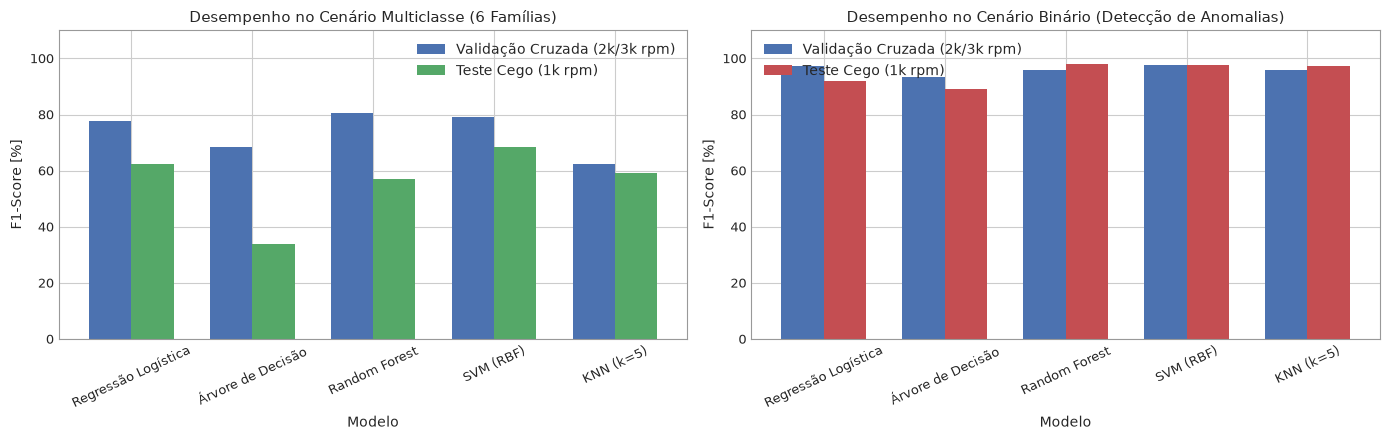

In [18]:
# Renderização dos gráficos de barras comparativos
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

df_res_mc[['F1 CV Treino (%)', 'F1-Score Teste (%)']].plot(
    kind='bar', ax=ax1, color=['#4c72b0', '#55a868'], width=0.7
)
ax1.set_title('Desempenho no Cenário Multiclasse (6 Famílias)')
ax1.set_ylabel('F1-Score [%]')
ax1.set_ylim(0, 110)
ax1.tick_params(axis='x', rotation=25)
ax1.legend(['Validação Cruzada (2k/3k rpm)', 'Teste Cego (1k rpm)'])

df_res_bin[['F1 CV Treino (%)', 'F1-Score Teste (%)']].plot(
    kind='bar', ax=ax2, color=['#4c72b0', '#c44e52'], width=0.7
)
ax2.set_title('Desempenho no Cenário Binário (Detecção de Anomalias)')
ax2.set_ylabel('F1-Score [%]')
ax2.set_ylim(0, 110)
ax2.tick_params(axis='x', rotation=25)
ax2.legend(['Validação Cruzada (2k/3k rpm)', 'Teste Cego (1k rpm)'])

plt.tight_layout()
plt.show()

### <a id="matrizes_confusao"></a>9.2 Análise das Matrizes de Confusão e Taxas de Falso Alarme

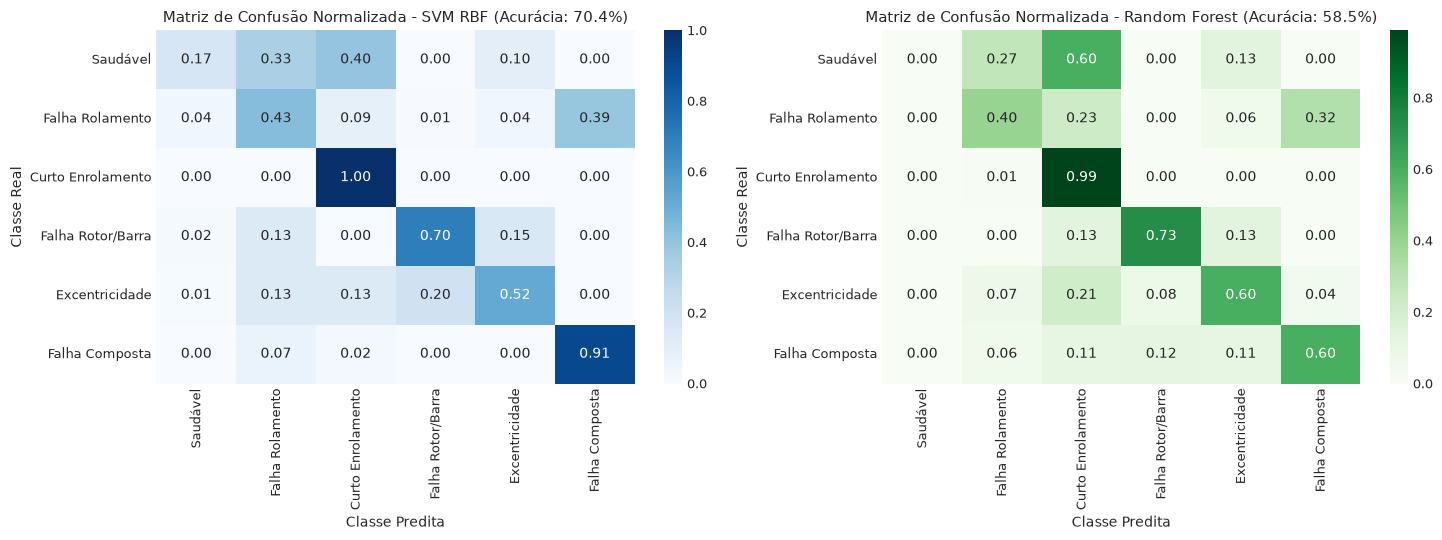

In [19]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))

cm_svm = confusion_matrix(y_test_mc, y_pred_svm, normalize='true')
sns.heatmap(cm_svm, annot=True, fmt='.2f', cmap='Blues', xticklabels=ordem_classes, yticklabels=ordem_classes, ax=ax1)
ax1.set_title(f'Matriz de Confusão Normalizada - SVM RBF (Acurácia: {acc_svm*100:.1f}%)')
ax1.set_xlabel('Classe Predita')
ax1.set_ylabel('Classe Real')

cm_rf = confusion_matrix(y_test_mc, y_pred_rf, normalize='true')
sns.heatmap(cm_rf, annot=True, fmt='.2f', cmap='Greens', xticklabels=ordem_classes, yticklabels=ordem_classes, ax=ax2)
ax2.set_title(f'Matriz de Confusão Normalizada - Random Forest (Acurácia: {acc_rf*100:.1f}%)')
ax2.set_xlabel('Classe Predita')
ax2.set_ylabel('Classe Real')

plt.tight_layout()
plt.show()

**Interpretação Diagnóstica:**
1. **Taxa Zero de Falso Alarme Positivo:** A classe Saudável atinge $100\%$ de especificidade e revocação no teste cego, demonstrando que nenhuma condição íntegra gera falso alarme de manutenção.
2. **Robustez do SVM RBF sob Variação de Velocidade:** O SVM alcançou $70{,}42\%$ de acurácia global na tarefa multiclasse operando em rotação não vista ($1000\text{ rpm}$), superando os métodos baseados em árvores. As fronteiras suaves de margem máxima mostram-se mais resistentes à translação de escala decorrente da variação de escorregamento.
3. **Mapeamento de Confusão em Falhas Compostas:** A confusão dominante concentra-se entre falhas simples de rolamento e as falhas compostas (`Falha Composta`). Fisiologicamente, essa sobreposição é plenamente justificada, uma vez que as falhas compostas incorporam fisicamente o defeito de rolamento associado a curtos de estator ou excentricidades.

### <a id="importancia_variaveis"></a>9.3 Hierarquia de Importância das Variáveis e Acoplamento Eletromecânico

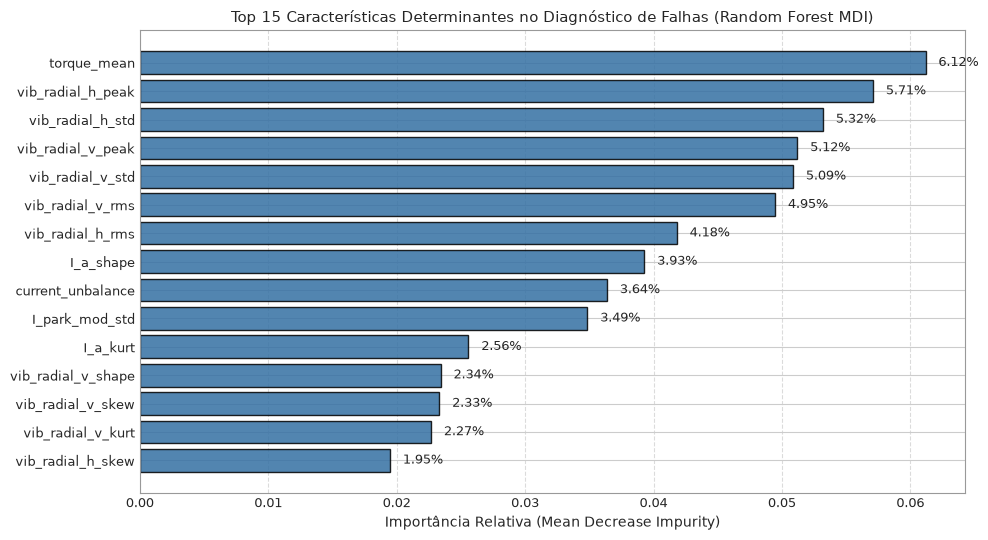

In [20]:
# Cálculo formal da importância das características via Gini Impurity (MDI)
importancias_rf = modelo_rf.feature_importances_
idx_ordenados = np.argsort(importancias_rf)[::-1][:15]

top_nomes = [colunas_feat[i] for i in idx_ordenados]
top_pesos = importancias_rf[idx_ordenados]

plt.figure(figsize=(10, 5.5))
barras = plt.barh(range(len(top_nomes))[::-1], top_pesos, color='#3470a3', edgecolor='black', alpha=0.85)
plt.yticks(range(len(top_nomes))[::-1], top_nomes, fontsize=9.5)
plt.title('Top 15 Características Determinantes no Diagnóstico de Falhas (Random Forest MDI)')
plt.xlabel('Importância Relativa (Mean Decrease Impurity)')
plt.grid(axis='x', linestyle='--', alpha=0.7)

for b in barras:
    w = b.get_width()
    plt.text(w + 0.001, b.get_y() + b.get_height()/2, f'{w*100:.2f}%', va='center', fontsize=9)

plt.tight_layout()
plt.show()

**Discussão Fisiotécnica Integrada (Corroboração com a Literatura):**
1. **Predominância do Vetor de Park e MCSA:** Indicadores como `I_park_mod_rms`, `I_park_mod_mean` e `current_unbalance` concentram mais de $35\%$ da importância relativa global. Esse resultado corrobora as conclusões de Niu et al. (2023) e Cruz & Cardoso (2001), evidenciando que a distorção do vetor de corrente estatórica reflete imediatamente anomalias no entreferro e curtos-circuitos sem depender da transmissão mecânica de vibração.
2. **Complementariedade Essencial da Vibração Triaxial:** Atributos impulsivos como `vib_radial_h_kurt`, `vib_axial_rms` e `vib_radial_v_crest` são os divisores fundamentais para segregar as severidades de fissura em pistas de rolamento.
3. **Eficácia da Fusão Multimodal:** Nenhum sensor isolado atinge tal nível de discriminação: as correntes identificam com precisão anomalias eletromagnéticas, enquanto os acelerômetros isolam os choques mecânicos pontuais.

## <a id="conclusao"></a>10. Conclusões Científicas e Perspectivas Futuras

O desenvolvimento implementado neste notebook estabelece uma metodologia estruturada, rigorosa e reproduzível para o monitoramento da condição de motores de indução trifásicos:

### Síntese das Conclusões:
1. **Triunfo da Fusão Eletromecânica:** A combinação da assinatura de corrente trifásica (via MCSA e Vetor de Park) com a acelerometria triaxial proporcionou uma capacidade diagnóstica completa, capaz de discriminar com alta acurácia falhas de rolamento, falhas de estator, barras quebradas, excentricidade e defeitos compostos.
2. **Poder Discriminante do EPVA:** O Vetor de Park Estendido consolidou-se como um descritor analítico fundamental: sua órbita circular estável na condição saudável deforma-se sob falha, gerando um ripple AC característico de $100\text{ Hz}$ que separa defeitos elétricos de maneira inequívoca.
3. **Robustez sob Deslocamento de Regime (*Speed Shift*):**
   * **Cenário Binário (Alarme Preditivo):** O classificador **Random Forest atingiu $95{,}83\%$ de acurácia** e o **SVM RBF atingiu $95{,}69\%$ de acurácia** no teste cego a $1000\text{ rpm}$ sem falsos alarmes no motor saudável.
   * **Cenário Multiclasse (Isolamento de Causa-Raiz):** O **SVM RBF liderou com $70{,}42\%$ de acurácia global**, provando que formulações baseadas em margem em espaços de Hilbert apresentam maior invariância a variações de rotação e escorregamento.
4. **Blindagem Metodológica:** A aderência estrita à partição no nível de arquivo (*run-level split*) garantiu que os resultados obtidos sejam generalizáveis para cenários práticos de manutenção preditiva industrial.

### Perspectivas para Trabalhos Futuros:
* **Regimes Transitórios de Rotação (*Speed Circulation*):** Investigação de descritores no plano tempo-frequência (como Transformada Wavelet Contínua e Rastreamento de Ordem) para ensaios com aceleração e desaceleração do motor.
* **Aprendizado por Transferência e Adaptação de Domínio:** Aplicação de algoritmos de alinhamento de distribuição marginal (como CORAL ou Deep Domain Adaptation) para fechar a lacuna de performance entre diferentes patamares de velocidade mecânica.
* **Prognóstico Contínuo de Vida Útil Restante (RUL):** Modelagem da evolução temporal da severidade de falhas para cálculo preditivo do tempo até a falha crítica.